# Example SIRDS model

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These tutorials use a CPU and the full original SIRDS bank. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `7a0813987944`](https://github.com/OJWatson/metis/tree/7a081398794492c82d92812b5801900f62f8639a).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Short uv setup cell shared by downloadable notebooks."""

import os
from pathlib import Path
import re
import shlex
import subprocess
import sys


def prepare_colab(revision):
    """Use the checkout's locked environment in Colab's active interpreter."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    if not (os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION")):
        print("Using your local METIS environment.")
        return
    # The source commit matches the results saved in this notebook.
    source = Path("/content/metis-tutorial")
    commands = f'''
set -euo pipefail
export PATH="$HOME/.local/bin:$PATH"
command -v uv >/dev/null || curl -LsSf https://astral.sh/uv/0.7.22/install.sh | sh
[ -d {source}/.git ] || git clone -q https://github.com/OJWatson/metis.git {source}
git -C {source} fetch -q origin {revision}
git -C {source} checkout -q --detach {revision}
uv sync --project {source} --python {shlex.quote(sys.executable)} --locked --inexact --no-dev --extra docs --no-editable
'''
    subprocess.run(
        ["bash", "-c", commands], check=True,
        env={**os.environ, "UV_PROJECT_ENVIRONMENT": sys.prefix, "UV_NO_MODIFY_PATH": "1"},
    )
    print("METIS is ready. If Colab reports a library-version conflict or asks for a restart, restart the session, then Run all.")


prepare_colab("7a081398794492c82d92812b5801900f62f8639a")


We use a stochastic SIRDS (Susceptible–Infected–Recovered–Dead–Susceptible)
compartmental model as a running example throughout the docs. The particulars
of the epidemic model are less important than its inputs and outputs: static
input parameters describe a simulation, and each run produces stochastic time
series of population counts.

People move from susceptible to infected, then either recover or die. Recovered
people can lose immunity and become susceptible again. The population is fixed
at 1,000, including people who have died.

| Input | Meaning |
|---|---|
| `I0` | Fraction of the population infected initially |
| `beta` | Transmission rate |
| `gamma` | Recovery rate |
| `omega` | Rate of loss of immunity |
| `mu` | Death rate among infected people |

## Code definition

The simulator is included in the installed package:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from metis.datasets.sirds import simulate_sirds

parameters = dict(I0=0.005, beta=0.4, gamma=0.1, omega=0.02, mu=0.01)
S, I, R, D = simulate_sirds(**parameters, N=1000, T=200, dt=1, seed=0)
print(f"{len(S)} time points, including the initial state")
print("Population conserved:", bool(np.all(S + I + R + D == 1000)))

201 time points, including the initial state
Population conserved: True


At each daily step, the simulator draws new infections and losses of immunity
from binomial distributions. A multinomial draw assigns each infected person
to recovery, death or remaining infected. For recovery, death and waning,
the step probability is $1-\exp(-\mathrm{rate}\times dt)$; infection also depends
on the current infected fraction. This is a discrete-time stochastic
simulation.

## Example realisations

Even with fixed input parameters, varying the random seed produces different
realisations. These are the differences a stochastic surrogate should learn
to reproduce.

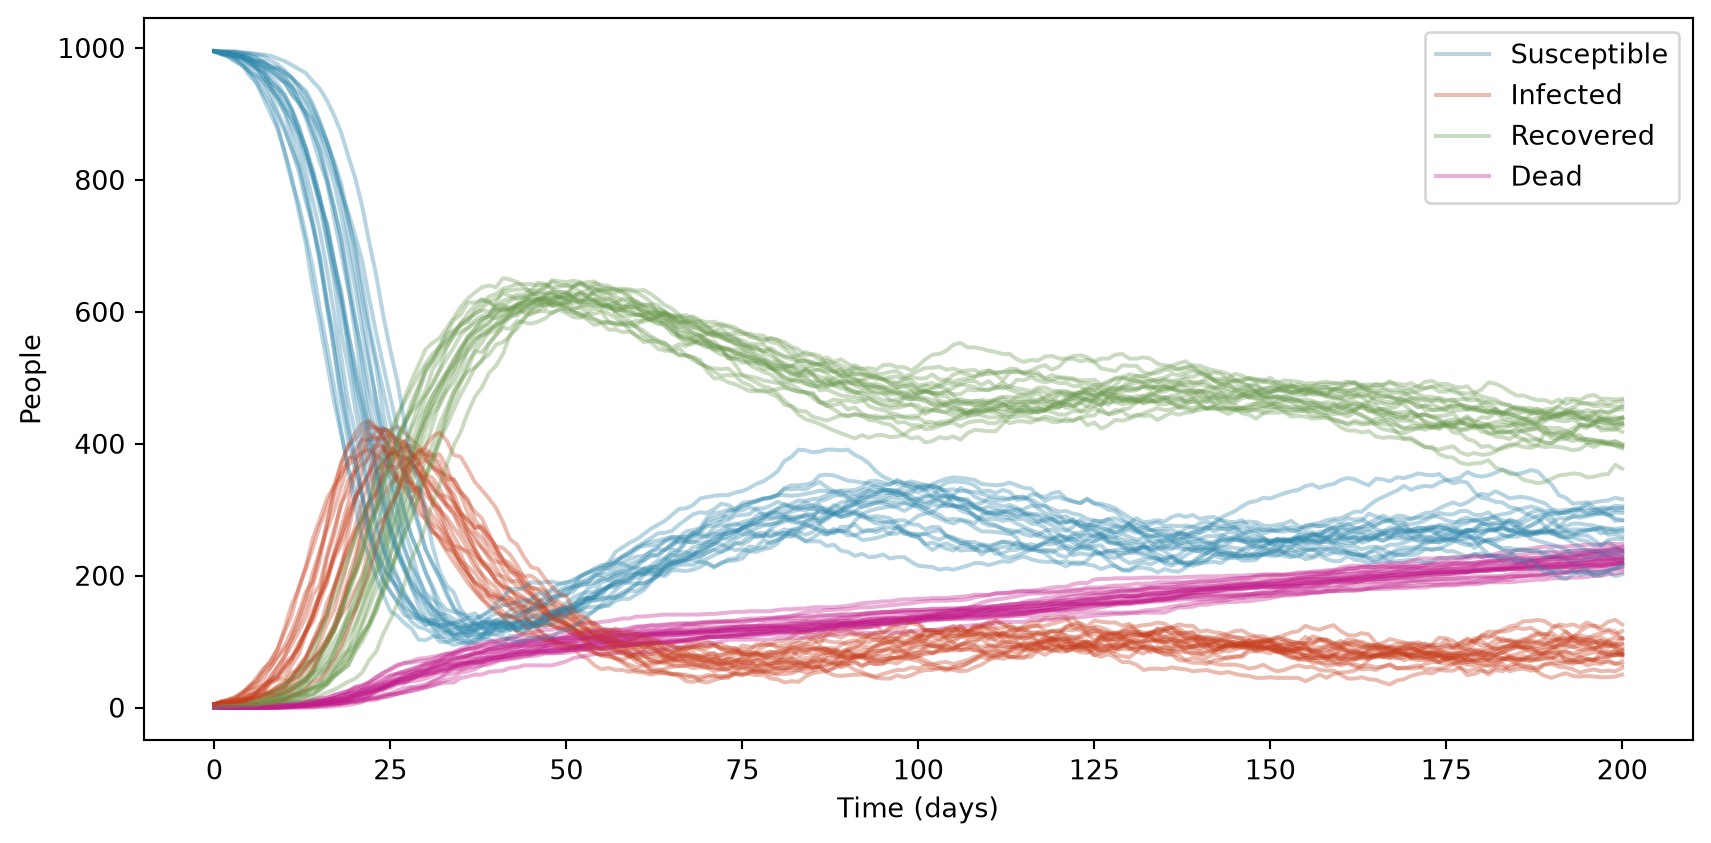

In [2]:
#| fig-cap: "SIRDS: 20 stochastic realisations with the same inputs, a population of 1,000 and daily steps. The variation comes from the simulator's random draws."
fig, ax = plt.subplots(figsize=(9, 4.5))
for seed in range(20):
    outputs = simulate_sirds(**parameters, N=1000, T=200, dt=1, seed=seed)
    for values, label, colour in zip(
        outputs,
        ["Susceptible", "Infected", "Recovered", "Dead"],
        ["#2E86AB", "#C73E1D", "#6A994E", "#C21B8A"],
    ):
        ax.plot(np.arange(201), values, color=colour, alpha=0.35,
                label=label if seed == 0 else None)
ax.set(xlabel="Time (days)", ylabel="People")
ax.legend()
fig.tight_layout()
plt.show()

*SIRDS: 20 stochastic realisations with the same inputs, a population of 1,000 and daily steps. The variation comes from the simulator's random draws.*

The bundled training bank is the original complete SIRDS dataset: 1,000
parameter settings with five realisations per setting. It contains days 1–200;
day zero is omitted.
In the data table the initial infected fraction is named `I_0`, and the four
outputs are `S_t`, `I_t`, `R_t` and `D_t`.

Next, [prepare the data for METIS](https://ojwatson.github.io/metis/basics/preparing-data.html).